In [1]:


from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")



In [2]:
DATA_PATH = Path("next_bill_amount_prediction_synthetic_dataset (1).csv")

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())


Rows: 17000 | Columns: 15


,customer_id,billing_month,plan_type,data_usage_gb,voice_calls,sms_count,...,data_charge,voice_charge,addon_charge,tax_amount,bill_amount,next_bill_amount
0,C00001,2024-01-01,Standard,5.83,315,15,...,0.0,7.5,0.0,73.17,479.67,496.78
1,C00001,2024-02-01,Standard,10.69,344,23,...,0.0,22.0,0.0,75.78,496.78,490.88
2,C00001,2024-03-01,Standard,7.64,334,2,...,0.0,17.0,0.0,74.88,490.88,500.32
3,C00001,2024-04-01,Standard,9.25,299,46,...,0.0,0.0,50.0,76.32,500.32,464.92
4,C00001,2024-05-01,Standard,8.99,340,29,...,0.0,20.0,0.0,70.92,464.92,472.00


In [3]:
df.info()

quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
})
display(quality_report)
print("Exact duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       17000 non-null  object 
 1   billing_month     17000 non-null  object 
 2   plan_type         17000 non-null  object 
 3   data_usage_gb     17000 non-null  float64
 4   voice_calls       17000 non-null  int64  
 5   sms_count         17000 non-null  int64  
 6   addon_data_gb     17000 non-null  float64
 7   plan_fee          17000 non-null  int64  
 8   discount_amount   17000 non-null  float64
 9   data_charge       17000 non-null  float64
 10  voice_charge      17000 non-null  float64
 11  addon_charge      17000 non-null  float64
 12  tax_amount        17000 non-null  float64
 13  bill_amount       17000 non-null  float64
 14  next_bill_amount  17000 non-null  float64
dtypes: float64(9), int64(3), object(3)
memory usage: 1.9+ MB


,data_type,missing_values,unique_values
customer_id,object,0,1000
billing_month,object,0,17
plan_type,object,0,3
data_usage_gb,float64,0,3495
voice_calls,int64,0,476
sms_count,int64,0,231
addon_data_gb,float64,0,3
plan_fee,int64,0,3
discount_amount,float64,0,4
data_charge,float64,0,6183


Exact duplicate rows: 0



#Clean types and check record quality

In [4]:
required_columns = [
    "customer_id", "billing_month", "plan_type", "data_usage_gb", "voice_calls",
    "sms_count", "addon_data_gb", "plan_fee", "discount_amount", "data_charge",
    "voice_charge", "addon_charge", "tax_amount", "bill_amount", "next_bill_amount",
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

for column in ["customer_id", "plan_type"]:
    df[column] = df[column].astype("string").str.strip().replace("", pd.NA)

df["billing_month"] = pd.to_datetime(df["billing_month"], errors="coerce")
numeric_columns = [column for column in required_columns
                   if column not in ["customer_id", "billing_month", "plan_type"]]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

rows_before = len(df)
df = df.drop_duplicates().copy()
print("Exact duplicates removed:", rows_before - len(df))

if df[["customer_id", "billing_month", "next_bill_amount"]].isna().any().any():
    raise ValueError("Some identifiers, dates or target values are missing or invalid. Check these rows.")
if not df["billing_month"].dt.is_month_start.all():
    raise ValueError("Expected month-start dates as billing-month labels.")
if df.duplicated(["customer_id", "billing_month"]).any():
    raise ValueError("Conflicting customer-month rows found. Review them before continuing.")
if np.isinf(df[numeric_columns].to_numpy()).any():
    raise ValueError("Infinite numeric values found. Review the source records.")
if (df[numeric_columns] < 0).any().any():
    raise ValueError("Negative usage or billing values found. Check whether they are valid credits.")

# Sort before calculating any customer history.
df = df.sort_values(["customer_id", "billing_month"]).reset_index(drop=True)
month_number = df["billing_month"].dt.year * 12 + df["billing_month"].dt.month
month_gap = month_number.groupby(df["customer_id"]).diff()
if month_gap.dropna().ne(1).any():
    raise ValueError("Monthly gaps found. Reindex customer histories before creating monthly lags.")

print("Customers:", df["customer_id"].nunique())
print("Input period:", df["billing_month"].min().date(), "to", df["billing_month"].max().date())
display(df.groupby("billing_month").size().rename("records").to_frame())


Exact duplicates removed: 0
Customers: 1000
Input period: 2024-01-01 to 2025-05-01


,records
billing_month,
2024-01-01,1000
2024-02-01,1000
2024-03-01,1000
2024-04-01,1000
2024-05-01,1000
2024-06-01,1000
2024-07-01,1000
2024-08-01,1000
2024-09-01,1000


Check bill totals and the target


In [5]:
charge_columns = ["plan_fee", "discount_amount", "data_charge", "voice_charge",
                  "addon_charge", "tax_amount", "bill_amount"]
complete_charges = df[charge_columns].notna().all(axis=1)
reconstructed_bill = (
    df["plan_fee"] - df["discount_amount"] + df["data_charge"]
    + df["voice_charge"] + df["addon_charge"] + df["tax_amount"]
)
bill_difference = (df["bill_amount"] - reconstructed_bill).abs()
print("Bills checked:", int(complete_charges.sum()))
print("Bills outside rounding tolerance:", int((bill_difference[complete_charges] > 0.02).sum()))
print("Largest rounding difference:", round(bill_difference.max(), 4))

following_bill = df.groupby("customer_id")["bill_amount"].shift(-1)
label_verified = following_bill.notna()
label_mismatch = label_verified & (df["next_bill_amount"] - following_bill).abs().gt(0.02)
print("Labels checked against next recorded bill:", int(label_verified.sum()))
print("Mismatched labels:", int(label_mismatch.sum()))
print("Labels without a following recorded bill:", int((~label_verified).sum()))
if label_mismatch.any():
    raise ValueError("Target mismatch found. Confirm the forecast horizon before continuing.")

# This flag decides which labels are suitable for evaluation. It is not a feature.
df["label_verified"] = label_verified


Bills checked: 17000
Bills outside rounding tolerance: 0
Largest rounding difference: 0.01
Labels checked against next recorded bill: 16000
Mismatched labels: 0
Labels without a following recorded bill: 1000


Set chronological boundaries before exploring patterns

In [6]:
df["forecast_month"] = df["billing_month"] + pd.offsets.MonthBegin(1)
verified_months = sorted(df.loc[df["label_verified"], "forecast_month"].unique())
if len(verified_months) < 9:
    raise ValueError("Not enough months for this train/validation/test setup.")

train_end = pd.Timestamp(verified_months[-7])
validation_end = pd.Timestamp(verified_months[-4])
train_mask = df["label_verified"] & df["forecast_month"].le(train_end)
validation_mask = (df["label_verified"] & df["forecast_month"].gt(train_end)
                   & df["forecast_month"].le(validation_end))
test_mask = df["label_verified"] & df["forecast_month"].gt(validation_end)
latest_mask = df["billing_month"].eq(df["billing_month"].max())

split_summary = []
for name, mask in [("Train", train_mask), ("Validation", validation_mask), ("Test", test_mask)]:
    part = df.loc[mask]
    split_summary.append({
        "split": name, "rows": len(part), "customers": part["customer_id"].nunique(),
        "input_start": part["billing_month"].min().date(),
        "input_end": part["billing_month"].max().date(),
        "target_start": part["forecast_month"].min().date(),
        "target_end": part["forecast_month"].max().date(),
    })
display(pd.DataFrame(split_summary))

# EDA uses only training rows so later outcomes do not guide our choices.
eda = df.loc[train_mask].copy()
display(eda.describe().T.round(2))


,split,rows,customers,input_start,input_end,target_start,target_end
0,Train,10000,1000,2024-01-01,2024-10-01,2024-02-01,2024-11-01
1,Validation,3000,1000,2024-11-01,2025-01-01,2024-12-01,2025-02-01
2,Test,3000,1000,2025-02-01,2025-04-01,2025-03-01,2025-05-01


,count,mean,min,25%,50%,75%,max,std
billing_month,10000,2024-05-16 19:12:00,2024-01-01 00:00:00,2024-03-01 00:00:00,2024-05-16 12:00:00,2024-08-01 00:00:00,2024-10-01 00:00:00,NaN
data_usage_gb,10000.0,15.089351,1.0,9.34,13.66,19.2,58.63,7.987505
voice_calls,10000.0,251.3251,0.0,201.0,252.0,304.0,518.0,77.150803
sms_count,10000.0,90.1374,0.0,62.0,90.0,118.0,269.0,40.559741
addon_data_gb,10000.0,1.0125,0.0,0.0,0.0,0.0,10.0,2.558906
plan_fee,10000.0,369.3,199.0,199.0,399.0,399.0,699.0,176.949261
discount_amount,10000.0,15.07,0.0,0.0,0.0,25.0,75.0,23.11003
data_charge,10000.0,64.8405,0.0,0.0,0.0,94.17,902.25,115.687252
voice_charge,10000.0,6.0686,0.0,0.0,0.0,2.0,109.0,13.736969
addon_charge,10000.0,10.125,0.0,0.0,0.0,0.0,100.0,25.589057


Explore bills, plans and customer variability

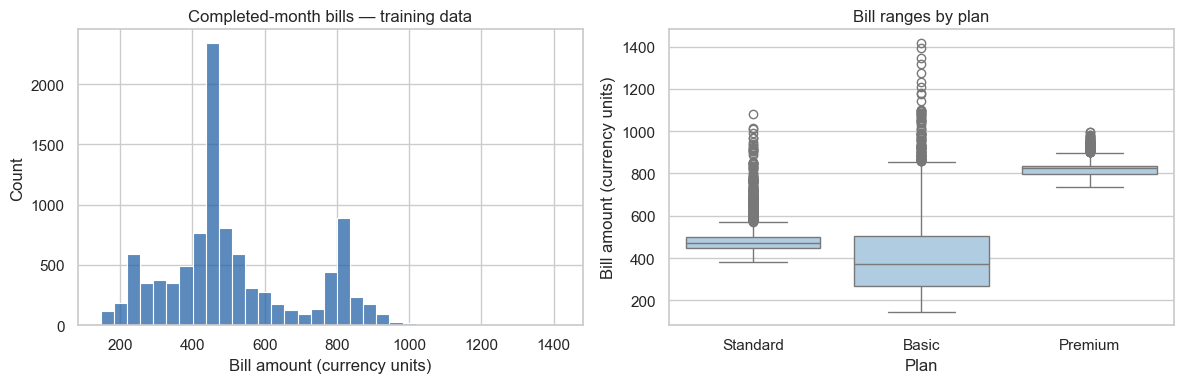

,records,customers,average_bill,median_bill,bill_std,average_data_gb
plan_type,,,,,,
Basic,4110,411,408.97,372.32,177.45,14.79
Premium,1750,175,825.99,824.82,43.58,15.60
Standard,4140,414,485.45,470.82,70.51,15.17


,count,mean,std
count,1000.0,1000.00,1000.00
mean,10.0,513.61,64.04
std,0.0,179.85,36.99
min,10.0,208.74,0.00
25%,10.0,420.81,36.92
50%,10.0,472.12,53.47
75%,10.0,558.34,83.80
max,10.0,1082.88,236.38


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=eda, x="bill_amount", bins=35, ax=axes[0], color="#2563a6")
axes[0].set_title("Completed-month bills — training data")
axes[0].set_xlabel("Bill amount (currency units)")
sns.boxplot(data=eda, x="plan_type", y="bill_amount", ax=axes[1], color="#a8cee8")
axes[1].set_title("Bill ranges by plan")
axes[1].set_xlabel("Plan")
axes[1].set_ylabel("Bill amount (currency units)")
plt.tight_layout()
plt.show()

display(eda.groupby("plan_type").agg(
    records=("bill_amount", "size"), customers=("customer_id", "nunique"),
    average_bill=("bill_amount", "mean"), median_bill=("bill_amount", "median"),
    bill_std=("bill_amount", "std"), average_data_gb=("data_usage_gb", "mean"),
).round(2))

customer_variability = eda.groupby("customer_id")["bill_amount"].agg(["count", "mean", "std"])
display(customer_variability.describe().round(2))


Check trends and possible seasonality

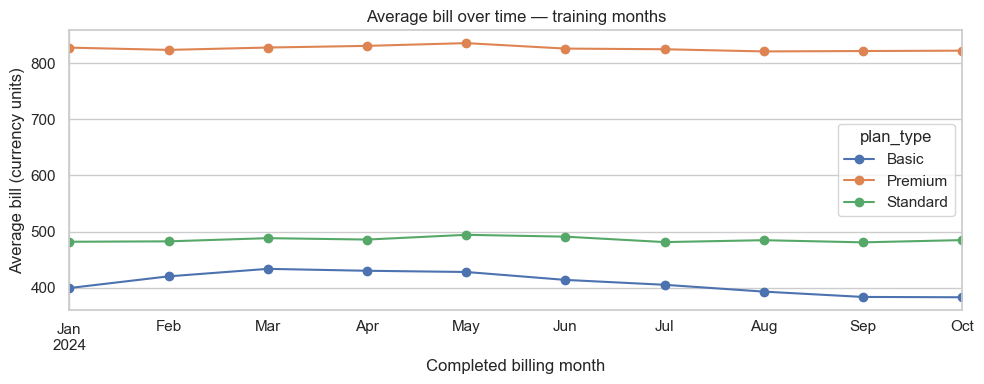

In [8]:
monthly_bill = eda.groupby(["billing_month", "plan_type"])["bill_amount"].mean().unstack()
monthly_bill.plot(figsize=(10, 4), marker="o")
plt.title("Average bill over time — training months")
plt.xlabel("Completed billing month")
plt.ylabel("Average bill (currency units)")
plt.tight_layout()
plt.show()


Look at cost drivers

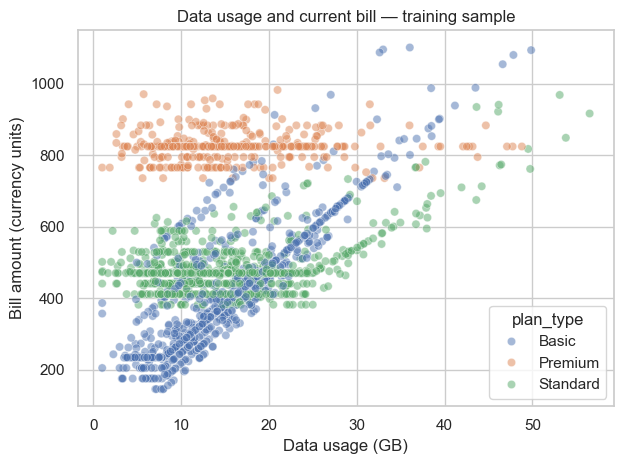

,plan_fee,discount_amount,data_charge,voice_charge,addon_charge,tax_amount,bill_amount
plan_type,,,,,,,
Basic,199.0,14.84,146.13,6.29,10.00,62.38,408.97
Premium,699.0,15.11,0.00,5.90,10.20,126.00,825.99
Standard,399.0,15.28,11.55,5.92,10.22,74.05,485.45


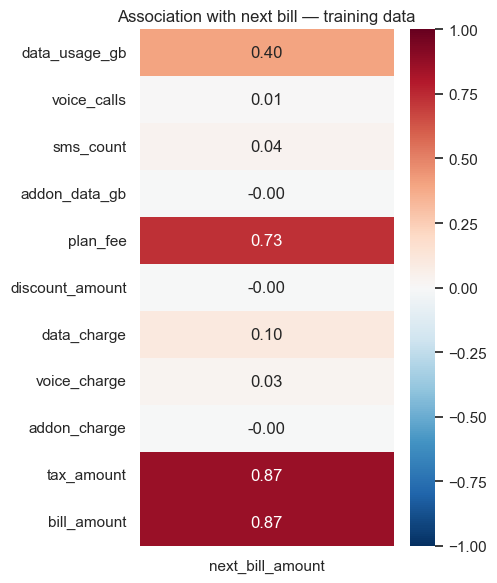

,next_bill_amount
tax_amount,0.865
bill_amount,0.865
plan_fee,0.734
data_usage_gb,0.403
data_charge,0.098
sms_count,0.036
voice_charge,0.028
voice_calls,0.006
discount_amount,-0.003
addon_charge,-0.005


In [9]:
sns.scatterplot(data=eda.sample(n=min(2000, len(eda)), random_state=42),
                x="data_usage_gb", y="bill_amount", hue="plan_type", alpha=0.5)
plt.title("Data usage and current bill — training sample")
plt.xlabel("Data usage (GB)")
plt.ylabel("Bill amount (currency units)")
plt.tight_layout()
plt.show()

cost_columns = ["plan_fee", "discount_amount", "data_charge", "voice_charge",
                "addon_charge", "tax_amount", "bill_amount"]
display(eda.groupby("plan_type")[cost_columns].mean().round(2))

correlation_columns = ["data_usage_gb", "voice_calls", "sms_count", "addon_data_gb",
                       "plan_fee", "discount_amount", "data_charge", "voice_charge",
                       "addon_charge", "tax_amount", "bill_amount", "next_bill_amount"]
correlations = eda[correlation_columns].corr()
next_bill_correlations = correlations[["next_bill_amount"]].drop(index="next_bill_amount")
plt.figure(figsize=(5, 6))
sns.heatmap(next_bill_correlations, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Association with next bill — training data")
plt.tight_layout()
plt.show()
display(next_bill_correlations.sort_values("next_bill_amount", ascending=False).round(3))


Flag large values without deleting them

In [10]:
q1 = eda.groupby("plan_type")["bill_amount"].transform(lambda values: values.quantile(0.25))
q3 = eda.groupby("plan_type")["bill_amount"].transform(lambda values: values.quantile(0.75))
iqr = q3 - q1
eda["bill_outside_iqr"] = (eda["bill_amount"] < q1 - 1.5 * iqr) | (eda["bill_amount"] > q3 + 1.5 * iqr)
display(eda.groupby("plan_type")["bill_outside_iqr"].agg(["sum", "mean"]).rename(
    columns={"sum": "bills_to_review", "mean": "fraction_of_records"}).round(3))
print("No rows were removed using the IQR rule.")


,bills_to_review,fraction_of_records
plan_type,,
Basic,95,0.023
Premium,101,0.058
Standard,363,0.088


No rows were removed using the IQR rule.


Create features from known history

In [11]:
features_df = df.copy()
customer_groups = features_df.groupby("customer_id", sort=False)

features_df["bill_lag_1"] = customer_groups["bill_amount"].shift(1)
features_df["bill_lag_2"] = customer_groups["bill_amount"].shift(2)
features_df["bill_mean_3"] = customer_groups["bill_amount"].transform(
    lambda values: values.rolling(window=3, min_periods=1).mean())
features_df["bill_std_3"] = customer_groups["bill_amount"].transform(
    lambda values: values.rolling(window=3, min_periods=2).std())
features_df["bill_change_1"] = features_df["bill_amount"] - features_df["bill_lag_1"]

features_df["usage_mean_3"] = customer_groups["data_usage_gb"].transform(
    lambda values: values.rolling(window=3, min_periods=1).mean())
features_df["usage_change_1"] = customer_groups["data_usage_gb"].diff()
features_df["history_months"] = customer_groups.cumcount() + 1
features_df["extra_charges"] = features_df[["data_charge", "voice_charge", "addon_charge"]].sum(
    axis=1, min_count=3)

# The next month's calendar date is already known at the forecast cutoff.
forecast_month_number = features_df["forecast_month"].dt.month
features_df["forecast_month_sin"] = np.sin(2 * np.pi * forecast_month_number / 12)
features_df["forecast_month_cos"] = np.cos(2 * np.pi * forecast_month_number / 12)

display(features_df[["customer_id", "billing_month", "bill_amount", "bill_lag_1",
                     "bill_lag_2", "bill_mean_3", "bill_change_1", "history_months"]].head(6))


,customer_id,billing_month,bill_amount,bill_lag_1,bill_lag_2,bill_mean_3,bill_change_1,history_months
0,C00001,2024-01-01,479.67,NaN,NaN,479.670000,NaN,1
1,C00001,2024-02-01,496.78,479.67,NaN,488.225000,17.11,2
2,C00001,2024-03-01,490.88,496.78,479.67,489.110000,-5.90,3
3,C00001,2024-04-01,500.32,490.88,496.78,495.993333,9.44,4
4,C00001,2024-05-01,464.92,500.32,490.88,485.373333,-35.40,5
5,C00001,2024-06-01,472.00,464.92,500.32,479.080000,7.08,6


Select inputs and separate the target

In [12]:
TARGET = "next_bill_amount"
feature_columns = [
    "plan_type", "data_usage_gb", "voice_calls", "sms_count", "addon_data_gb",
    "plan_fee", "discount_amount", "data_charge", "voice_charge", "addon_charge",
    "tax_amount", "bill_amount", "bill_lag_1", "bill_lag_2", "bill_mean_3",
    "bill_std_3", "bill_change_1", "usage_mean_3", "usage_change_1",
    "history_months", "extra_charges", "forecast_month_sin", "forecast_month_cos",
]

X_train = features_df.loc[train_mask, feature_columns].copy()
X_validation = features_df.loc[validation_mask, feature_columns].copy()
X_test = features_df.loc[test_mask, feature_columns].copy()
y_train = features_df.loc[train_mask, TARGET].copy()
y_validation = features_df.loc[validation_mask, TARGET].copy()
y_test = features_df.loc[test_mask, TARGET].copy()

# No target is exported with these future-demo inputs.
X_latest = features_df.loc[latest_mask, feature_columns].copy()
metadata_columns = ["customer_id", "billing_month", "forecast_month", "plan_type",
                    "bill_amount", "bill_mean_3", "history_months"]
train_metadata = features_df.loc[train_mask, metadata_columns].copy()
validation_metadata = features_df.loc[validation_mask, metadata_columns].copy()
test_metadata = features_df.loc[test_mask, metadata_columns].copy()
latest_metadata = features_df.loc[latest_mask, metadata_columns].copy()

print("Inputs per record:", len(feature_columns))
print("Train:", X_train.shape, "Validation:", X_validation.shape, "Test:", X_test.shape)
print("Latest demo inputs:", X_latest.shape)
display(X_train.isna().sum().loc[lambda counts: counts > 0].rename("missing_before_imputation"))


Inputs per record: 23
Train: (10000, 23) Validation: (3000, 23) Test: (3000, 23)
Latest demo inputs: (1000, 23)


bill_lag_1        1000
bill_lag_2        2000
bill_std_3        1000
bill_change_1     1000
usage_change_1    1000
Name: missing_before_imputation, dtype: int64

Fit preprocessing on training data only

In [13]:
categorical_features = ["plan_type"]
numeric_features = [column for column in feature_columns if column not in categorical_features]

# Convert pandas' missing-string marker to the marker understood by the imputer.
for table in [X_train, X_validation, X_test, X_latest]:
    table["plan_type"] = table["plan_type"].astype(object).fillna(np.nan)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("category", categorical_pipeline, categorical_features),
], verbose_feature_names_out=False)

X_train_ready = preprocessor.fit_transform(X_train)
X_validation_ready = preprocessor.transform(X_validation)
X_test_ready = preprocessor.transform(X_test)
X_latest_ready = preprocessor.transform(X_latest)
encoded_feature_names = preprocessor.get_feature_names_out().tolist()

print("Encoded inputs per record:", len(encoded_feature_names))
display(pd.DataFrame(X_train_ready, columns=encoded_feature_names).head())


Encoded inputs per record: 25


,data_usage_gb,voice_calls,sms_count,addon_data_gb,plan_fee,discount_amount,...,extra_charges,forecast_month_sin,forecast_month_cos,plan_type_Basic,plan_type_Premium,plan_type_Standard
0,-1.159287,0.825372,-1.852604,-0.395697,0.167853,-0.652130,...,-0.598334,1.210653,1.099191,0.0,0.0,1.0
1,-0.550807,1.201278,-1.655355,-0.395697,0.167853,-0.652130,...,-0.480350,1.387719,0.298734,0.0,0.0,1.0
2,-0.932672,1.071655,-2.173135,-0.395697,0.167853,-0.652130,...,-0.521034,1.210653,-0.501722,0.0,0.0,1.0
3,-0.731097,0.617975,-1.088262,1.558361,0.167853,0.429705,...,-0.252519,0.726900,-1.087697,0.0,0.0,1.0
4,-0.763650,1.149429,-1.507417,-0.395697,0.167853,0.429705,...,-0.496624,0.066082,-1.302179,0.0,0.0,1.0


Confirm the data is ready

In [14]:
for name, matrix in [("Train", X_train_ready), ("Validation", X_validation_ready),
                     ("Test", X_test_ready), ("Latest", X_latest_ready)]:
    assert np.isfinite(matrix).all(), f"{name} contains a missing or infinite value."
    assert matrix.shape[1] == len(encoded_feature_names)
    print(name, "ready:", matrix.shape)

assert TARGET not in feature_columns
assert "customer_id" not in feature_columns
assert "label_verified" not in feature_columns
assert train_metadata["forecast_month"].max() < validation_metadata["forecast_month"].min()
assert validation_metadata["forecast_month"].max() < test_metadata["forecast_month"].min()
assert train_metadata["forecast_month"].max() <= validation_metadata["billing_month"].min()
assert validation_metadata["forecast_month"].max() <= test_metadata["billing_month"].min()
assert len(X_train_ready) == len(y_train)
assert len(X_validation_ready) == len(y_validation)
assert len(X_test_ready) == len(y_test)
print("Checks passed. No regression model has been trained yet.")


Train ready: (10000, 25)
Validation ready: (3000, 25)
Test ready: (3000, 25)
Latest ready: (1000, 25)
Checks passed. No regression model has been trained yet.


baselines for the next step

In [15]:
baselines = {}
for name, metadata in [("train", train_metadata), ("validation", validation_metadata), ("test", test_metadata)]:
    baselines[name] = metadata[["customer_id", "billing_month", "forecast_month"]].copy()
    baselines[name]["current_bill_baseline"] = metadata["bill_amount"].to_numpy()
    baselines[name]["recent_average_baseline"] = metadata["bill_mean_3"].to_numpy()

print("Baseline inputs saved for train, validation and test.")


Baseline inputs saved for train, validation and test.


Save the prepared data

In [16]:
import sklearn

OUTPUT_DIR = Path("prepared_data")
OUTPUT_DIR.mkdir(exist_ok=True)

model_data = {
    "feature_columns": feature_columns,
    "encoded_feature_names": encoded_feature_names,
    "X_train": X_train, "X_validation": X_validation, "X_test": X_test, "X_latest": X_latest,
    "X_train_ready": X_train_ready, "X_validation_ready": X_validation_ready,
    "X_test_ready": X_test_ready, "X_latest_ready": X_latest_ready,
    "y_train": y_train, "y_validation": y_validation, "y_test": y_test,
    "train_metadata": train_metadata, "validation_metadata": validation_metadata,
    "test_metadata": test_metadata, "latest_metadata": latest_metadata,
    "baselines": baselines,
}
joblib.dump(model_data, OUTPUT_DIR / "model_data.joblib")
joblib.dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib")

for name, matrix, target, metadata in [
    ("train", X_train_ready, y_train, train_metadata),
    ("validation", X_validation_ready, y_validation, validation_metadata),
    ("test", X_test_ready, y_test, test_metadata),
    ("latest", X_latest_ready, None, latest_metadata),
]:
    # All CSVs use matching row order within a split.
    pd.DataFrame(matrix, columns=encoded_feature_names).to_csv(OUTPUT_DIR / f"X_{name}.csv", index=False)
    metadata.to_csv(OUTPUT_DIR / f"metadata_{name}.csv", index=False)
    if target is not None:
        target.reset_index(drop=True).to_csv(OUTPUT_DIR / f"y_{name}.csv", index=False)

preparation_notes = {
    "source_file": DATA_PATH.name,
    "forecast_horizon": "One month ahead after current-month billing is finalized",
    "split_basis": "Forecast month, using labels verified against the following recorded bill",
    "train_target_end": str(train_end.date()),
    "validation_target_end": str(validation_end.date()),
    "test_target_end": str(test_metadata["forecast_month"].max().date()),
    "rows": {"train": len(X_train), "validation": len(X_validation),
             "test": len(X_test), "latest_demo": len(X_latest)},
    "raw_features": feature_columns,
    "encoded_features": encoded_feature_names,
    "history_rule": "Customer-specific backward-looking history; current completed month included",
    "evaluation_rule": "Rolling one-month forecasts; earlier realized bills may update history; preprocessing stays fixed",
    "label_check": {"verified_rows": int(df["label_verified"].sum()),
                    "unverified_rows": int((~df["label_verified"]).sum())},
    "limitations": ["Synthetic data; generation process and currency not supplied",
                    "Insufficient history to establish annual seasonality",
                    "Latest supplied target labels excluded from evaluation because they cannot be cross-checked",
                    "No forecast accuracy, prediction drivers, uncertainty or high-bill detection evaluated in Step 1"],
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__},
}
with open(OUTPUT_DIR / "preparation_notes.json", "w", encoding="utf-8") as file:
    json.dump(preparation_notes, file, indent=2)

print("Prepared files saved to:", OUTPUT_DIR.resolve())
print("Next step: train regression models, compare them on validation data, then evaluate once on the held-out test period.")


Prepared files saved to: C:\Users\saipr\OneDrive\Desktop\HCL\prepared_data
Next step: train regression models, compare them on validation data, then evaluate once on the held-out test period.
